# What an experience curve can tell the Spurs

Joseph Smarrelli · September 2026

This notebook recalculates selected findings from the included derived tables. It does not refit the underlying models. See the repository README for the complete source-data build and the accompanying article for interpretation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
p = root / 'projects' / '06_development_curves_R'

## Recalculate the result
The assertions check that the article’s reported quantities agree with the delivered tables.

In [2]:
d = pd.read_csv(p / 'spurs_core_projection.csv')
assert np.allclose(d.rapm + d.expected_step, d.projected_rapm)
assert (d.step_lo <= d.step_hi).all()
display(d)

,player_name,experience,minutes,rapm,expected_step,step_lo,step_hi,projected_rapm
0,Carter Bryant,0,765.931667,-1.763376,0.536086,0.379423,0.656118,-1.227290
1,Stephon Castle,1,1791.821667,1.645061,0.395574,0.308176,0.469372,2.040635
2,Dylan Harper,0,1377.433333,2.153803,0.536086,0.379423,0.656118,2.689889
3,Victor Wembanyama,2,1658.831667,8.164191,0.165290,0.100356,0.243697,8.329482


## Inspect the estimates

In [3]:
display(pd.read_csv(p / 'development_curve.csv'))

,experience,effect,lo,hi
0,0,0.000000,0.000000,0.000000
1,1,0.536086,0.379423,0.656118
2,2,0.931660,0.692355,1.123601
3,3,1.096951,0.865186,1.298809
4,4,1.145142,0.913722,1.368218
5,5,1.206855,0.961442,1.441878
6,6,1.279497,0.967013,1.539872
7,7,1.327174,0.961024,1.607053
8,8,1.321099,0.908294,1.625829
9,9,1.260926,0.830940,1.596198


## Figures

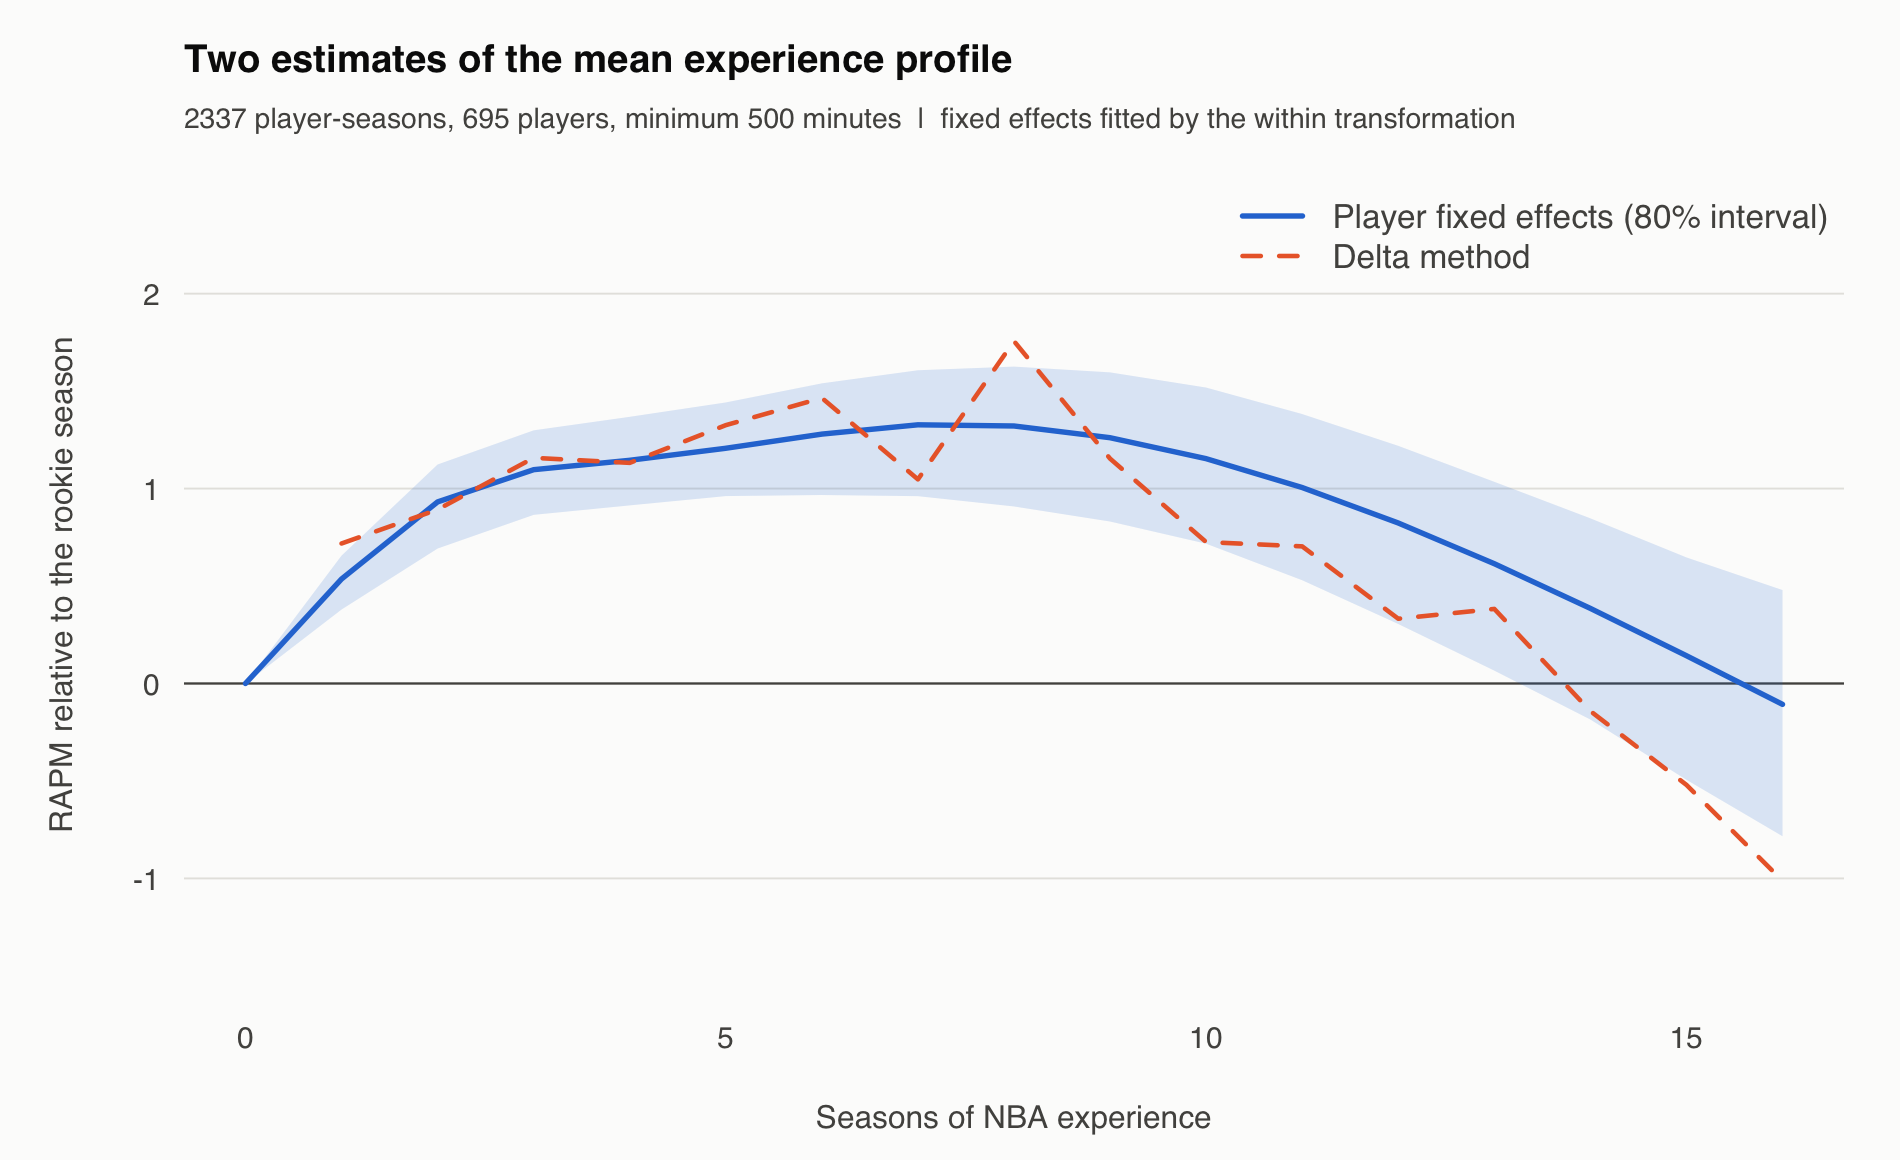

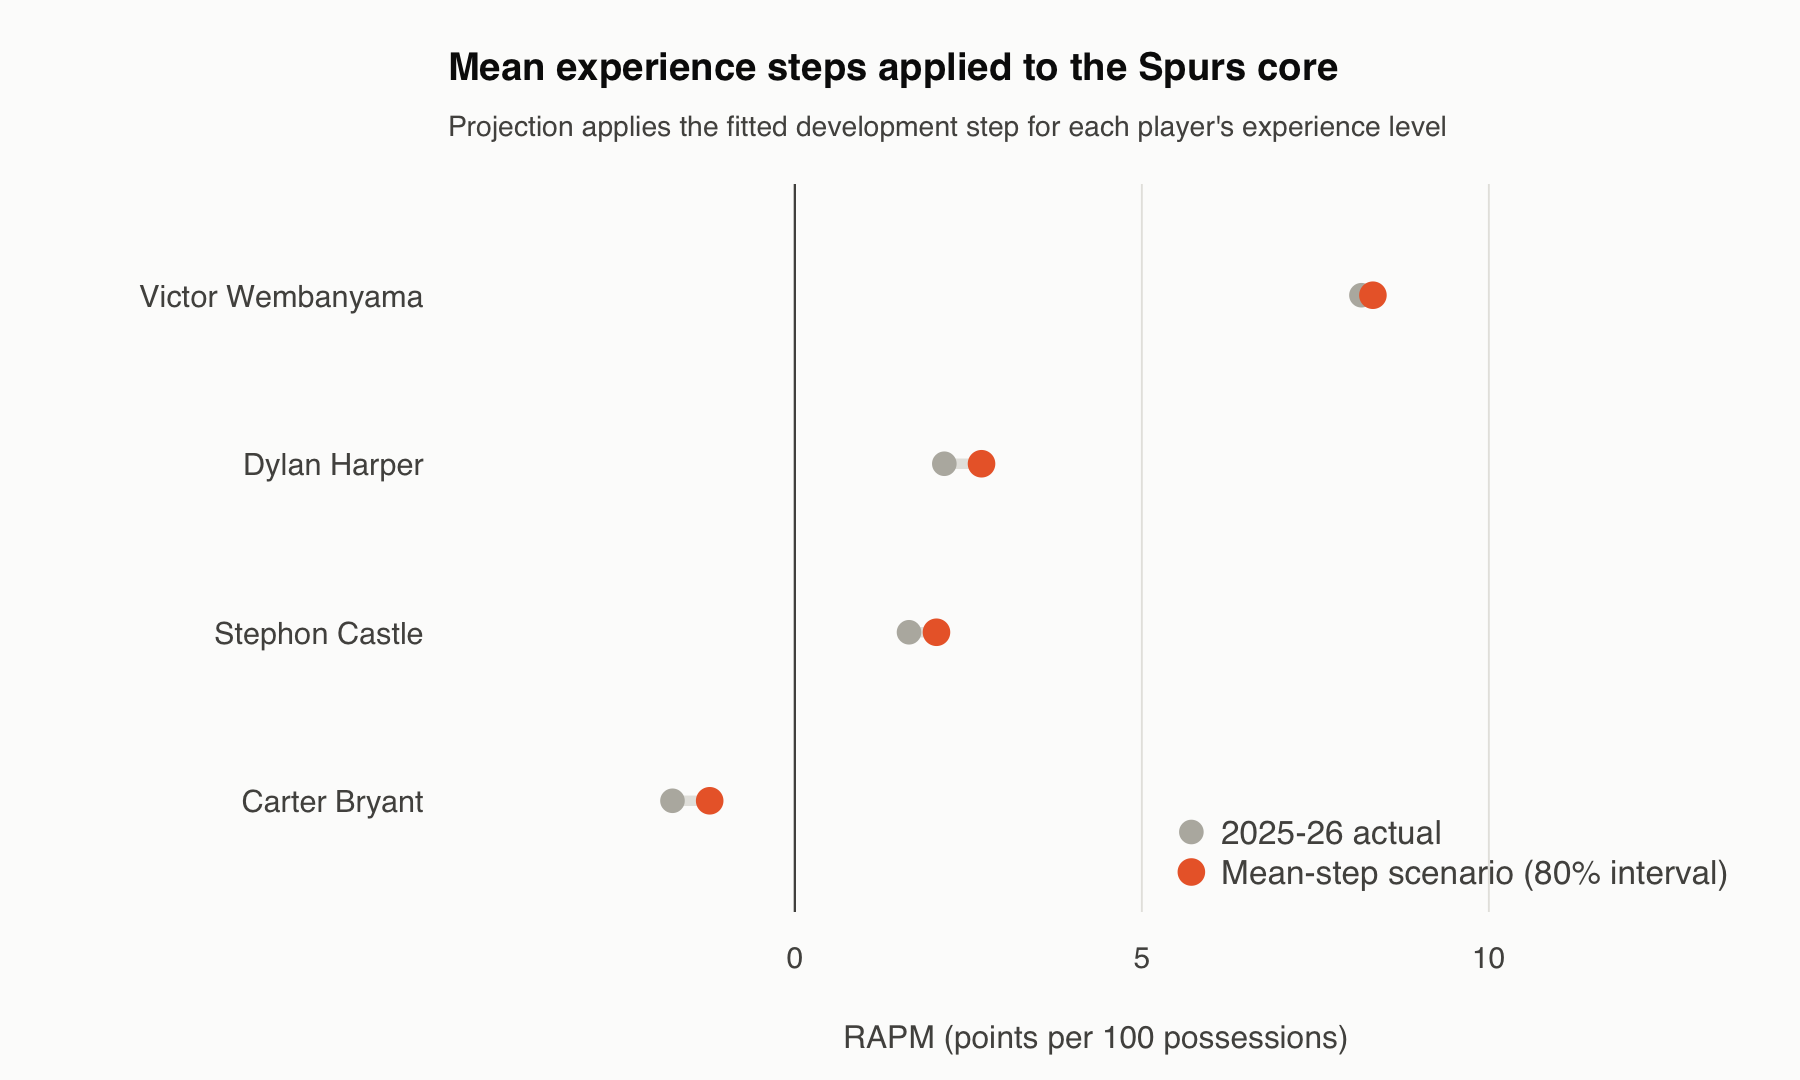

In [4]:
display(Image(filename=str(root / 'projects/06_development_curves_R/figures/development_curve.png')))
display(Image(filename=str(root / 'projects/06_development_curves_R/figures/spurs_core_projection.png')))

## Interpretation limits
The curve estimates a population mean from observed careers. Its bootstrap interval describes the mean step, not the full uncertainty of an individual player forecast. The underlying model is fitted by the accompanying R script.